# nxbsupersynth vs SuperSynth on MRIxFields 3T and 7T: visual check of `results_summary.md`

Each section shows one finding of `results_summary.md`, first as numbers (from `results/*.csv`), then on
real images: **image | SuperSynth (converted to the nxbsupersynth labels) | nxbsupersynth prediction | disagreement**.

- SuperSynth segmentations: `data_shared/test/mrixfields/segmentations/supersynth/`, converted on the fly
  exactly as in `evaluate.py` (left → right ids, WM-hypointensities → WM, ventricles / CSF / extra-cerebral → 0).
  The original SuperSynth labels are kept to name what lies under each disagreement (e.g. ventricles, CSF).
- Label maps are shown with compact indices 1..18 (legend), not the raw SuperSynth ids.
- Sections 1–2 cover **3T and 7T**; image sections 3–8 use **3T**; section 9 repeats the checks on **7T**.
- Kernel: conda env `nxb`.

In [1]:
import sys
from pathlib import Path
from multiprocessing import Pool
import numpy as np, pandas as pd, nibabel as nib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm, TwoSlopeNorm
from matplotlib.patches import Patch
from IPython.display import display

HERE = Path.cwd()                      # .../evaluation/mrixfields/supersynth_nxbsupersynth
TRAIN = HERE.parents[4]                # fixed_tree_training
sys.path.insert(0, str(HERE))
import evaluate as ev                  # label space and SuperSynth conversion used by the evaluation
RES = HERE / "results"
PRED = ev.PRED_DIR
SSRAW = ev.GT_DIR
IMG = TRAIN / "data_shared/test/mrixfields/images"
FIELD = "3T"
FIELDS = ["3T", "7T"]
CONTRASTS = ["T1w", "FLAIR", "T2w"]
CCOL = {"T1w": "#2a78d6", "FLAIR": "#eb6834", "T2w": "#1baf7a"}   # fixed identity colors
assert PRED.exists() and SSRAW.exists(), "run from evaluation/mrixfields/supersynth_nxbsupersynth"

per_case_all = pd.read_csv(RES / "per_case.csv")
per_case_mean_all = pd.read_csv(RES / "per_case_mean.csv").assign(group=lambda x: x.subject.str[4])
summ_all = pd.read_csv(RES / "summary_contrast_field.csv")
per_case = per_case_all[per_case_all.field == FIELD]
per_case_mean = per_case_mean_all[per_case_mean_all.field == FIELD]
summ = summ_all[summ_all.field == FIELD]
NS = ev.N                              # 18 structures
SHORT = {1: "Brainstem", 2: "WM", 3: "Cortex", 4: "Cb WM", 5: "Cb cortex", 6: "Thalamus", 7: "Caudate",
         8: "Putamen", 9: "Pallidum", 10: "Hippocampus", 11: "Amygdala", 12: "Accumbens", 13: "Optic chiasm",
         14: "Hypothal noMB", 15: "Fornix", 16: "Mammillary b.", 17: "Basal forebrain", 18: "Septal nuc"}
assert all(ev.STRUCTURES[k] for k in SHORT)

# SuperSynth LUT: id -> name
SS_NAMES = {}
for line in (TRAIN.parents[1] / "libraries/nextbrain-utils/nextbrain_utils/lut/SuperSynthWholeLUT.txt").read_text().splitlines():
    p = line.split()
    if len(p) >= 2 and p[0].isdigit():
        SS_NAMES[int(p[0])] = p[1]

LAB_COLORS = ["#000000", "#779fb0", "#f5f5f5", "#cd3e4e", "#dcf8a4", "#e69422", "#00760e", "#7abadc",
              "#ec0db0", "#0d30ff", "#dcd814", "#67ffff", "#ffa500", "#ff4500", "#7fff00", "#a020f0",
              "#ffb6c1", "#8b4513", "#bf7fbf"]
LAB_CMAP = ListedColormap(LAB_COLORS); LAB_NORM = BoundaryNorm(np.arange(-0.5, NS + 1.5), NS + 1)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "font.size": 9})
display(per_case_mean_all.groupby(["field", "contrast"]).size().unstack().rename_axis(None, axis=1))

,FLAIR,T1w,T2w
field,,,
3T,163,163,162
7T,104,255,101


In [2]:
# ---------- loading and plotting helpers ----------
def canon(img):
    return nib.as_closest_canonical(img)          # RAS: x=L->R, y=P->A, z=I->S

def load_case(contrast, case, field=None):
    """image, SuperSynth converted (0..18), prediction (0..18), original SuperSynth labels"""
    field = field or case.split("_ses-")[1].split("_")[0]
    im = canon(nib.load(IMG / contrast / field / f"{case}_0000.nii.gz"))
    raw = np.rint(np.asanyarray(canon(nib.load(SSRAW / contrast / field / f"{case}_0000.nii.gz")).dataobj)).astype(np.int32)
    pr = canon(nib.load(PRED / contrast / field / f"{case}.nii.gz"))
    d = dict(contrast=contrast, case=case, zooms=im.header.get_zooms()[:3],
             img=np.asanyarray(im.dataobj).astype(np.float32), raw=raw,
             gt=ev.to_index(raw, ev.GT_LUT).astype(np.uint8),
             pred=ev.to_index(pr.dataobj, ev.PRED_LUT).astype(np.uint8))
    m = d["gt"] > 0
    d["lo"], d["hi"] = np.percentile(d["img"][m], [1, 99.5])
    return d

def take(vol, axis, idx):
    return np.rot90(np.take(vol, idx, axis=axis))   # anterior/superior up

def centroid(mask):
    return [int(round(c)) for c in np.argwhere(mask).mean(0)]

def crop_box(mask, axis, margin_mm=15, zooms=(0.5,) * 3):
    proj = np.rot90(mask.any(axis=axis)); r, c = np.where(proj)
    other = [a for a in range(3) if a != axis]
    mr, mc = int(margin_mm / zooms[other[1]]), int(margin_mm / zooms[other[0]])
    return (max(r.min() - mr, 0), r.max() + mr, max(c.min() - mc, 0), c.max() + mc)

def show_row(axs, d, axis, idx, box=None, err="labels", title=True):
    """image | SuperSynth | nxbsupersynth | disagreement (err='labels' or 'tissue')"""
    im, gt, pr = (take(d[k], axis, idx) for k in ("img", "gt", "pred"))
    if box: sl = (slice(box[0], box[1]), slice(box[2], box[3])); im, gt, pr = im[sl], gt[sl], pr[sl]
    for a in axs:
        a.imshow(im, cmap="gray", vmin=d["lo"], vmax=d["hi"], interpolation="none"); a.set_xticks([]); a.set_yticks([])
    for a, s in ((axs[1], gt), (axs[2], pr)):
        a.imshow(np.ma.masked_equal(s, 0), cmap=LAB_CMAP, norm=LAB_NORM, alpha=0.55, interpolation="none")
    if err == "labels":
        axs[3].imshow(np.ma.masked_where(gt == pr, np.ones_like(gt)), cmap=ListedColormap(["#e0115f"]), alpha=0.7, interpolation="none")
        t3 = "disagreement (any label)"
    else:
        e = np.zeros(gt.shape); e[(pr > 0) & (gt == 0)] = 1; e[(pr == 0) & (gt > 0)] = 2
        axs[3].imshow(np.ma.masked_equal(e, 0), cmap=ListedColormap(["#e0115f", "#1c5cab"]), vmin=1, vmax=2, alpha=0.75, interpolation="none")
        t3 = "red: tissue only in nxbsupersynth\nblue: tissue only in SuperSynth"
    if title:
        for a, t in zip(axs, (f"{d['contrast']}  {d['case']}", "SuperSynth (converted)", "nxbsupersynth prediction", t3)):
            a.set_title(t, fontsize=8)

def label_legend(fig, labels, **kw):
    fig.legend(handles=[Patch(color=LAB_COLORS[l], label=f"{l} {SHORT[l]}") for l in labels],
               loc="lower center", ncol=min(len(labels), 9), frameon=False, fontsize=8, **kw)

def raw_breakdown(d, mask, top=8):
    """original SuperSynth labels inside `mask`: share of voxels and mL"""
    v = d["raw"][mask]; ids, n = np.unique(v, return_counts=True); o = np.argsort(-n)[:top]
    ml = np.prod(d["zooms"]) / 1000
    return pd.DataFrame({"supersynth_label": ids[o], "name": [SS_NAMES.get(int(i), "Unknown" if i == 0 else "?") for i in ids[o]],
                         "mL": (n[o] * ml).round(2), "share_%": (100 * n[o] / n.sum()).round(1)})

def zoom_fig(d, labels, title, margin=12, legend_extra=(1, 2, 3, 6)):
    m = np.isin(d["gt"], labels) | np.isin(d["pred"], labels); cen = centroid(np.isin(d["gt"], labels))
    fig, axs = plt.subplots(3, 4, figsize=(12, 9.5))
    for row, axis in enumerate((0, 1, 2)):          # sagittal, coronal, axial
        show_row(axs[row], d, axis, cen[axis], box=crop_box(m, axis, margin, d["zooms"]), title=(row == 0))
    fig.suptitle(title, y=1.0); label_legend(fig, sorted(set(labels) | set(legend_extra)))
    plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.show()

## 1. Overall Dice per contrast and field

Per-case Dice averaged over the 18 structures. Subjects `sub-P*` and `sub-R*` are plotted separately.
The `R` subjects are different people at 3T and 7T; only the 20 `P` subjects were scanned at both field
strengths (paired plot below).

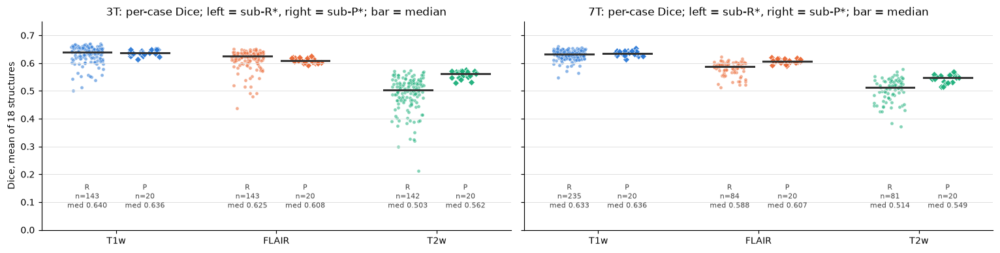

count          mean           std           min           50%  \
field              3T     7T     3T     7T     3T     7T     3T     7T     3T   
contrast group                                                                  
FLAIR    P       20.0   20.0  0.609  0.607  0.009  0.008  0.592  0.590  0.608   
         R      143.0   84.0  0.614  0.582  0.036  0.024  0.438  0.513  0.625   
T1w      P       20.0   20.0  0.636  0.635  0.010  0.009  0.615  0.614  0.636   
         R      143.0  235.0  0.631  0.631  0.032  0.015  0.501  0.548  0.640   
T2w      P       20.0   20.0  0.558  0.545  0.014  0.015  0.529  0.514  0.562   
         R      142.0   81.0  0.491  0.503  0.062  0.042  0.212  0.372  0.503   

                         max         
field              7T     3T     7T  
contrast group                       
FLAIR    P      0.607  0.626  0.620  
         R      0.588  0.652  0.624  
T1w      P      0.636  0.650  0.653  
         R      0.633  0.670  0.661  
T2w      P      0.549  0.576  0.568  
         R      0.514  0.573  0.579

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6), sharey=True)
rng = np.random.default_rng(0)
for ax, fld in zip(axes, FIELDS):
    q = per_case_mean_all[per_case_mean_all.field == fld]
    for i, c in enumerate(CONTRASTS):
        for j, (g, mk) in enumerate((("R", "o"), ("P", "D"))):
            v = q[(q.contrast == c) & (q.group == g)].dice.values
            x = i + (j - 0.5) * 0.36 + rng.uniform(-0.1, 0.1, len(v))
            ax.scatter(x, v, s=12 if g == "R" else 22, marker=mk, color=CCOL[c], alpha=0.55 if g == "R" else 0.95,
                       edgecolor="white", linewidth=0.5)
            ax.plot([i + (j - 0.5) * 0.36 - 0.15, i + (j - 0.5) * 0.36 + 0.15], [np.median(v)] * 2, color="#333", lw=2)
            ax.text(i + (j - 0.5) * 0.36, 0.08, f"{g}\nn={len(v)}\nmed {np.median(v):.3f}", ha="center", fontsize=7.5, color="#444")
    ax.set_xticks(range(3)); ax.set_xticklabels(CONTRASTS); ax.set_ylim(0, 0.75)
    ax.set_title(f"{fld}: per-case Dice; left = sub-R*, right = sub-P*; bar = median")
    ax.grid(axis="y", color="#ddd", lw=0.6)
axes[0].set_ylabel("Dice, mean of 18 structures"); plt.tight_layout(); plt.show()
display(per_case_mean_all.groupby(["field", "contrast", "group"]).dice.describe()[["count", "mean", "std", "min", "50%", "max"]].round(3).unstack(0))

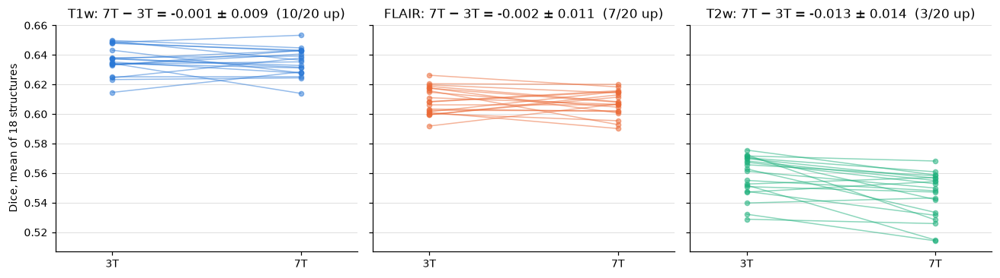

In [4]:
# same subject at 3T and 7T (sub-P* only)
w = per_case_mean_all[per_case_mean_all.group == "P"].pivot_table(index=["subject", "contrast"], columns="field", values="dice").dropna()
fig, axs = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for a, c in zip(axs, CONTRASTS):
    t = w.xs(c, level="contrast")
    for _, r in t.iterrows():
        a.plot([0, 1], [r["3T"], r["7T"]], color=CCOL[c], alpha=0.5, lw=1, marker="o", ms=4)
    dd = t["7T"] - t["3T"]
    a.set_title(f"{c}: 7T − 3T = {dd.mean():+.3f} ± {dd.std():.3f}  ({(dd > 0).sum()}/{len(dd)} up)")
    a.set_xticks([0, 1]); a.set_xticklabels(["3T", "7T"]); a.set_xlim(-0.3, 1.3); a.grid(axis="y", color="#ddd", lw=0.6)
axs[0].set_ylabel("Dice, mean of 18 structures"); plt.tight_layout(); plt.show()

**What we see.** T1w and FLAIR are tight (most cases 0.58–0.67) and `R`/`P` subjects behave the same. On T2w the
20 `sub-P*` cases are close to T1w (median 0.56 at 3T), but the `sub-R*` cases spread down to 0.21 (section 7).
For the same `P` subjects, 7T and 3T are equal on T1w/FLAIR (−0.001/−0.002) and slightly lower at 7T on T2w (−0.013, 17/20 subjects).
The mean over 18 structures is pulled down by three classes that are defined differently in the two label sets (section 6).

## 2. Per-structure Dice and volume bias

Columns: contrast × field. Left: mean Dice. Right: median relative volume difference
(prediction − SuperSynth) / SuperSynth; red = nxbsupersynth larger, blue = smaller (colors clipped at ±100 %).

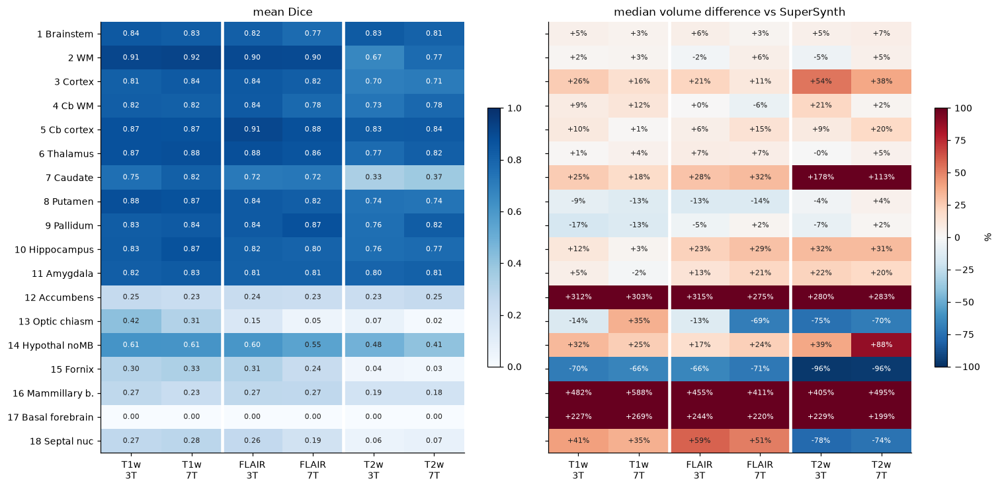

In [5]:
COLS = [(c, f) for c in CONTRASTS for f in FIELDS]
sa = summ_all[summ_all.label > 0]
dice = sa.pivot(index="label", columns=["contrast", "field"], values="dice_mean")[COLS]
vol = sa.pivot(index="label", columns=["contrast", "field"], values="rel_vol_diff_pct_median")[COLS]
ylab = [f"{l} {SHORT[l]}" for l in dice.index]
fig, axs = plt.subplots(1, 2, figsize=(14, 6.8))
im0 = axs[0].imshow(dice.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
im1 = axs[1].imshow(vol.values.clip(-100, 100), cmap="RdBu_r", norm=TwoSlopeNorm(0, -100, 100), aspect="auto")
for a, M, fmt in ((axs[0], dice.values, "{:.2f}"), (axs[1], vol.values, "{:+.0f}%")):
    a.set_xticks(range(len(COLS))); a.set_xticklabels([f"{c}\n{f}" for c, f in COLS]); a.set_yticks(range(NS)); a.set_yticklabels(ylab)
    for k in (1.5, 3.5): a.axvline(k, color="white", lw=3)
    for (r, c), v in np.ndenumerate(M):
        dark = (a is axs[0] and v > 0.6) or (a is axs[1] and abs(v) > 60)
        a.text(c, r, fmt.format(v), ha="center", va="center", fontsize=7.5, color="white" if dark else "#222")
axs[1].set_yticklabels([])
axs[0].set_title("mean Dice"); axs[1].set_title("median volume difference vs SuperSynth")
fig.colorbar(im0, ax=axs[0], shrink=0.6); fig.colorbar(im1, ax=axs[1], shrink=0.6, label="%")
plt.tight_layout(); plt.show()

### Where does each SuperSynth structure go? (confusion matrices over all cases)

Row = SuperSynth class, column = nxbsupersynth label, each row normalized to 100 %. Unlike the
evaluation (where they are all background), the rows keep apart what SuperSynth calls **outside the
brain** (0 and extra-cerebral 9xx), **ventricles** (lateral, inferior lateral, 3rd, 4th) and **CSF** (24),
to see where nxbsupersynth puts them. Saved to `results/confusion_<field>.npz`.

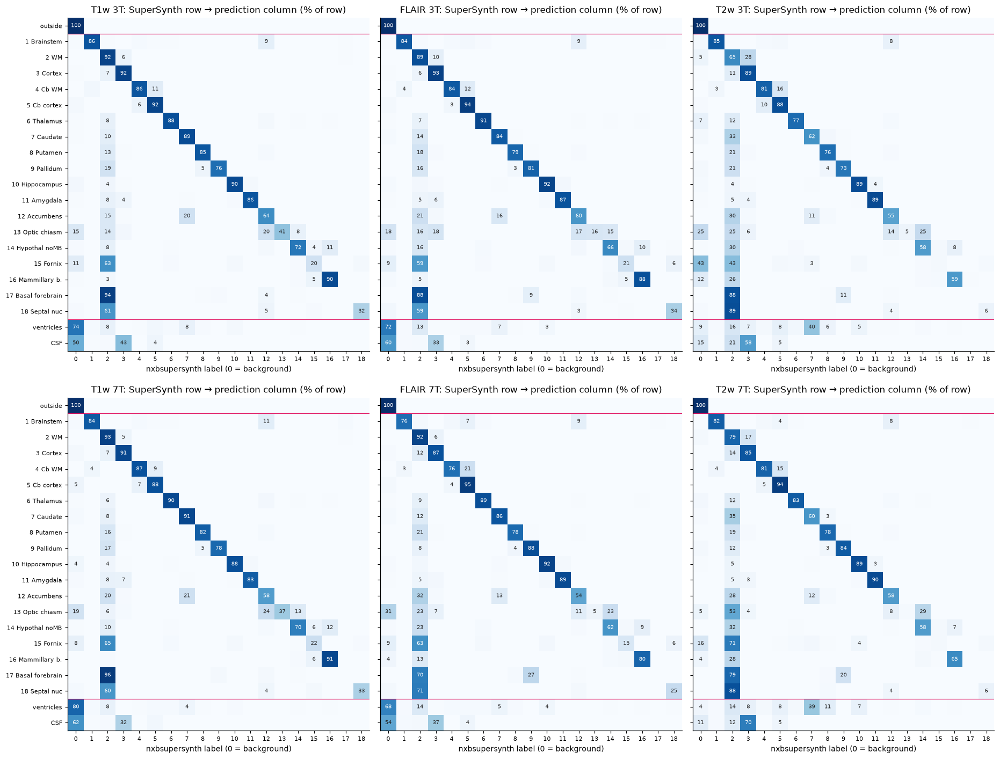

In [6]:
ROW_NAMES = ["outside"] + [SHORT[l] for l in range(1, NS + 1)] + ["ventricles", "CSF"]
ROW_LUT = ev.GT_LUT.copy()
ROW_LUT[[4, 5, 14, 15, 43, 44]] = NS + 1
ROW_LUT[24] = NS + 2
NR, NC = NS + 3, NS + 1

def conf_case(item):
    c, f, case = item
    raw = np.asanyarray(nib.load(SSRAW / c / f / f"{case}_0000.nii.gz").dataobj)
    pr = np.asanyarray(nib.load(PRED / c / f / f"{case}.nii.gz").dataobj)
    r = ev.to_index(raw, ROW_LUT); k = np.minimum(ev.to_index(pr, ev.PRED_LUT), NS)
    return c, np.bincount(r.ravel() * NC + k.ravel(), minlength=NR * NC).reshape(NR, NC)

CONF_ALL = {}
for fld in FIELDS:
    conf_file = RES / f"confusion_{fld}.npz"
    if conf_file.exists():
        CONF_ALL[fld] = dict(np.load(conf_file)); continue
    q = per_case_mean_all[per_case_mean_all.field == fld]
    conf = {c: np.zeros((NR, NC), np.int64) for c in CONTRASTS}
    with Pool(48) as pool:
        for c, m in pool.imap_unordered(conf_case, [(r.contrast, fld, r.case) for r in q.itertuples()], chunksize=2):
            conf[c] += m
    np.savez(conf_file, **conf); CONF_ALL[fld] = conf

fig, axes = plt.subplots(2, 3, figsize=(17, 13))
for (fld, c), a in zip([(f, c) for f in FIELDS for c in CONTRASTS], axes.ravel()):
    M = CONF_ALL[fld][c].astype(float); M = 100 * M / M.sum(1, keepdims=True)
    a.imshow(M, cmap="Blues", vmin=0, vmax=100)
    for (r, k), v in np.ndenumerate(M):
        if v >= 3: a.text(k, r, f"{v:.0f}", ha="center", va="center", fontsize=6.5, color="white" if v > 55 else "#222")
    a.set_xticks(range(NC)); a.set_xticklabels(range(NC), fontsize=7); a.set_yticks(range(NR))
    a.set_yticklabels([f"{i} {n}" if 0 < i <= NS else n for i, n in enumerate(ROW_NAMES)] if c == CONTRASTS[0] else [""] * NR, fontsize=7)
    a.set_xlabel("nxbsupersynth label (0 = background)"); a.set_title(f"{c} {fld}: SuperSynth row → prediction column (% of row)")
    for y in (0.5, NS + 0.5): a.axhline(y, color="#e0115f", lw=0.8)
plt.tight_layout(); plt.show()

**What we see.** - Large structures sit on the diagonal (WM, cortex, cerebellum, thalamus, hippocampus, amygdala: 84–94 % on T1w/FLAIR).
- **Column 2 (WM)** takes 8–21 % of every deep gray nucleus: borders with the white matter differ.
- **Basal forebrain (row 17): 0 % on the diagonal**, 88–96 % goes to WM. **Fornix** (59–71 %) and **septal nuclei** (59–89 %) also go mostly to WM.
  These are not border errors: the network was trained with other definitions of these classes (section 6).
- **Brainstem → accumbens (column 12), 8–11 %:** the network's "accumbens" covers the upper midbrain (section 6).
- **CSF row:** 32–43 % of SuperSynth CSF is labeled cortex on T1w/FLAIR, 58–70 % cortex + 12–21 % WM on T2w (section 4).
- **Ventricles row:** 68–80 % background on T1w/FLAIR, but **only 4–9 % on T2w**: on T2w the ventricles are filled with caudate (39–40 %),
  WM, putamen, hippocampus… (sections 5 and 7).

## 3. Representative subject (median Dice) in the three contrasts

A `sub-P*` subject with all three contrasts whose per-case Dice is closest to each contrast's median at 3T.
Mid-axial, mid-coronal and mid-sagittal slices through the center of the brain.

representative subject: sub-P0018 {'FLAIR': 0.619, 'T1w': 0.633, 'T2w': 0.532}  medians: {'FLAIR': 0.623, 'T1w': 0.639, 'T2w': 0.515}


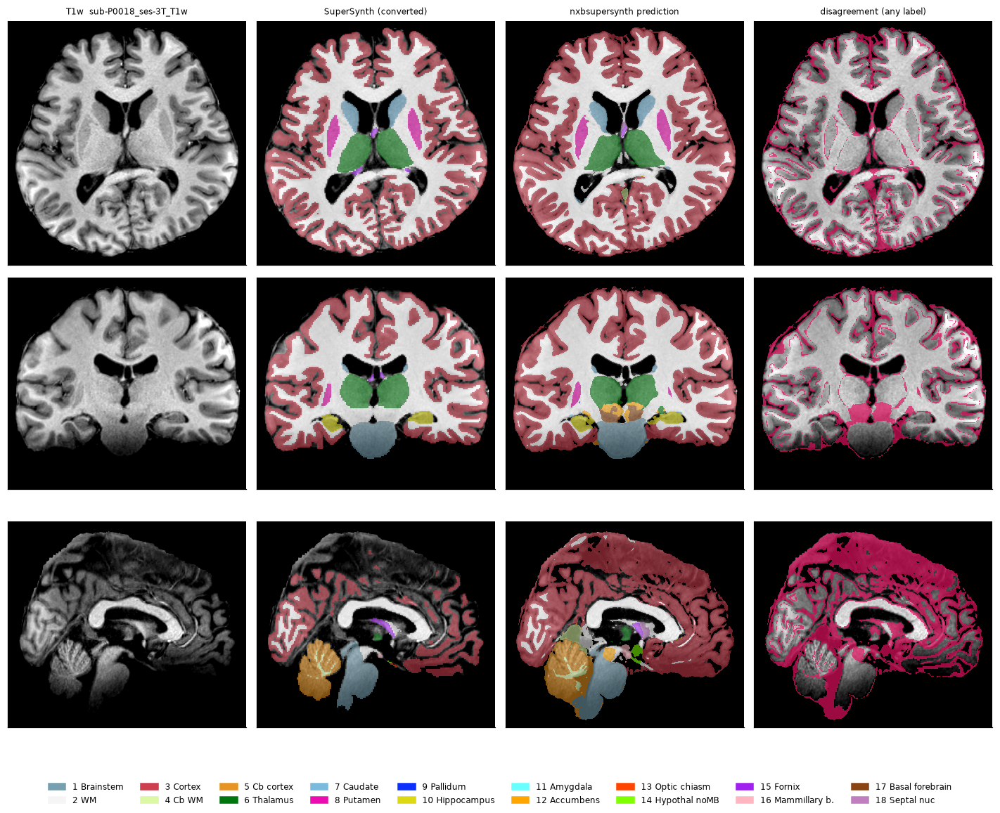

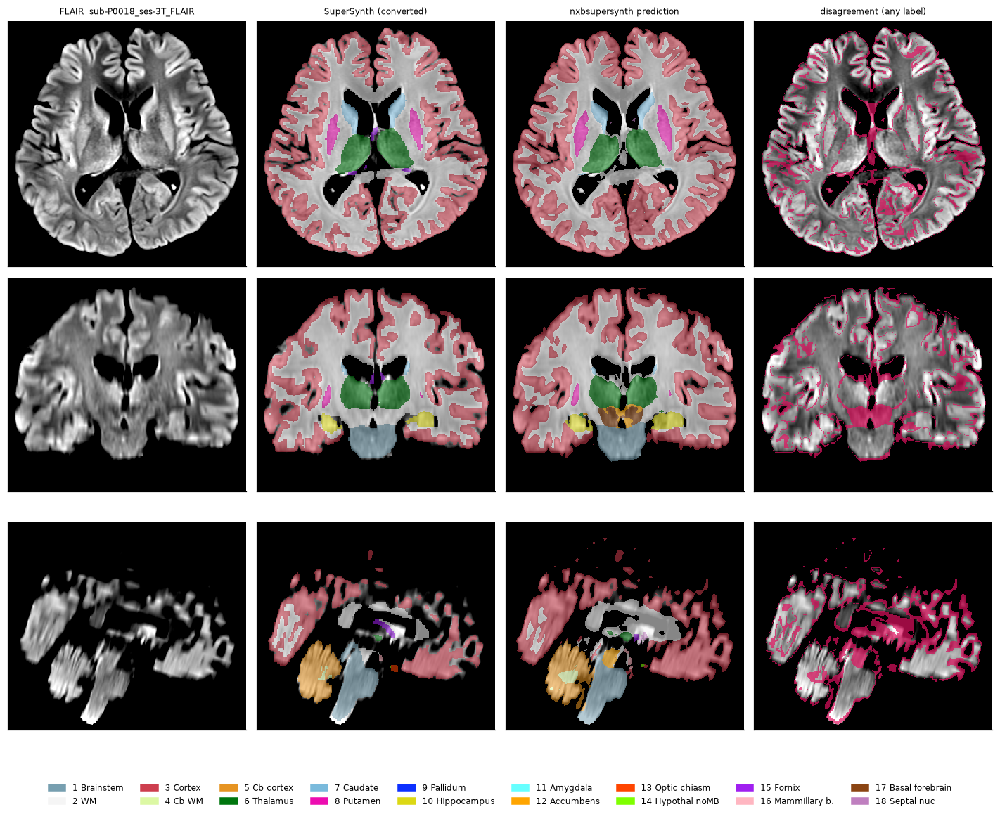

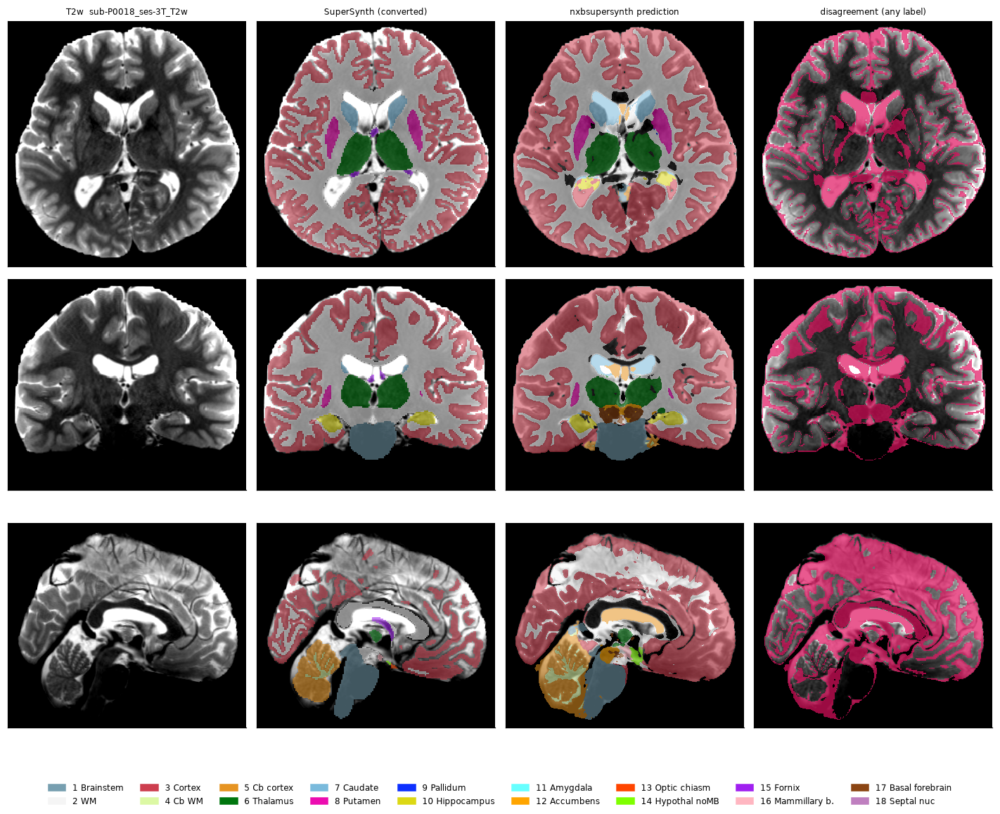

In [7]:
wide = per_case_mean.pivot_table(index="subject", columns="contrast", values="dice").dropna()
med = per_case_mean.groupby("contrast").dice.median()
score = (wide[CONTRASTS] - med[CONTRASTS]).abs().sum(axis=1)
REP = score[score.index.str.startswith("sub-P")].idxmin()
print("representative subject:", REP, wide.loc[REP].round(3).to_dict(), " medians:", med.round(3).to_dict())
REP_CASES = {c: load_case(c, f"{REP}_ses-{FIELD}_{c}") for c in CONTRASTS}
for c in CONTRASTS:
    d = REP_CASES[c]; cen = centroid(d["gt"] > 0)
    fig, axs = plt.subplots(3, 4, figsize=(13, 10.5))
    for row, axis in enumerate((2, 1, 0)):              # axial, coronal, sagittal
        show_row(axs[row], d, axis, cen[axis], box=crop_box(d["gt"] > 0, axis, 5, d["zooms"]), title=(row == 0))
    label_legend(fig, range(1, NS + 1)); plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.show()

**What we see.** The large structures look alike in both segmentations. The visible differences are the cortex drawn
out to the pial surface (sulci filled), the region below the thalami (the network's "accumbens" / "basal forebrain"
in the midbrain), and, on T2w, tissue labels inside the lateral ventricles.

## 4. Finding: the cortex (and the whole brain) is larger than SuperSynth's

Disagreement column: **red** = tissue in nxbsupersynth but background in SuperSynth (after conversion),
**blue** = the opposite. The table lists the *original* SuperSynth labels under the red voxels.

Sum of the 18 structures (whole labeled brain), mean over cases:


,field,contrast,supersynth_mL,nxbsupersynth_mL,diff_pct_mean,diff_pct_std
0,3T,T1w,1031.5,1174.9,13.9,2.9
1,3T,FLAIR,1085.8,1184.5,9.2,2.2
2,3T,T2w,1057.8,1314.3,24.5,6.5
3,7T,T1w,1050.5,1145.8,9.1,1.8
4,7T,FLAIR,1120.3,1218.0,8.8,2.0
5,7T,T2w,1060.4,1309.9,23.9,5.9


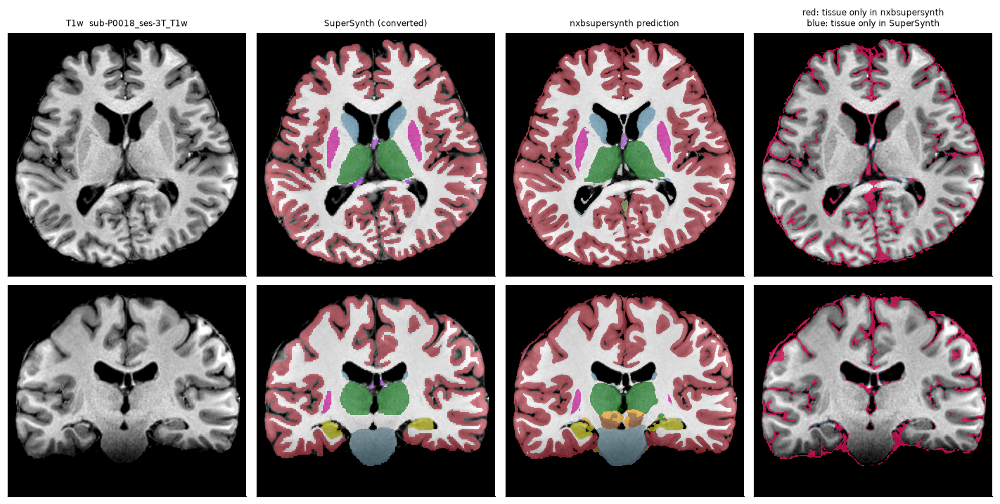

T1w: 251 mL tissue only in nxbsupersynth; original SuperSynth labels there:


,supersynth_label,name,mL,share_%
0,24,CSF,234.58,93.5
1,0,Unknown,6.02,2.4
2,4,Left-Lateral-Ventricle,2.92,1.2
3,15,4th-Ventricle,2.58,1.0
4,43,Right-Lateral-Ventricle,1.63,0.6
5,914,Vein,1.43,0.6


...and the nxbsupersynth labels it gets: {'WM': '3%', 'Cortex': '84%', 'Cb cortex': '8%'}


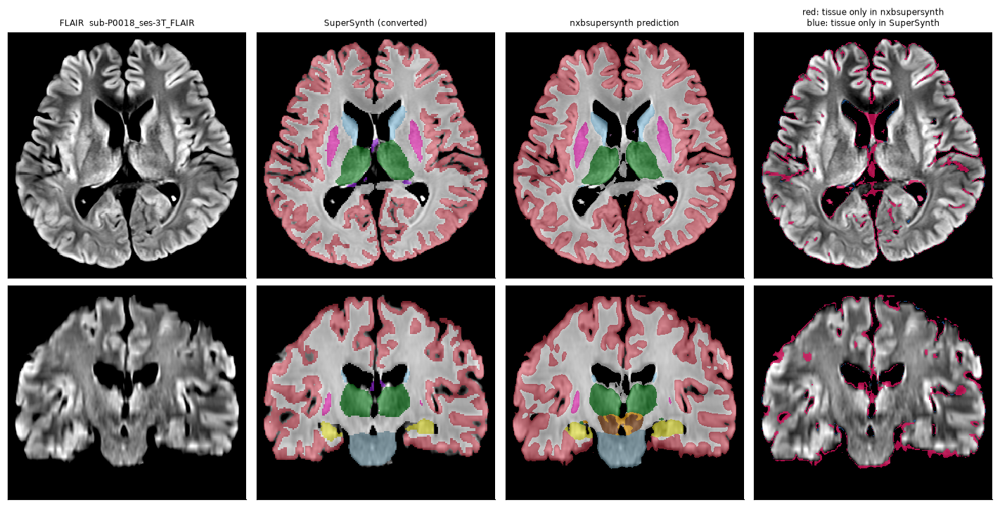

FLAIR: 128 mL tissue only in nxbsupersynth; original SuperSynth labels there:


,supersynth_label,name,mL,share_%
0,24,CSF,114.90,89.8
1,4,Left-Lateral-Ventricle,4.14,3.2
2,43,Right-Lateral-Ventricle,3.05,2.4
3,0,Unknown,2.93,2.3
4,15,4th-Ventricle,1.26,1.0
5,5,Left-Inf-Lat-Vent,0.66,0.5


...and the nxbsupersynth labels it gets: {'Brainstem': '2%', 'WM': '10%', 'Cortex': '76%', 'Cb cortex': '10%'}


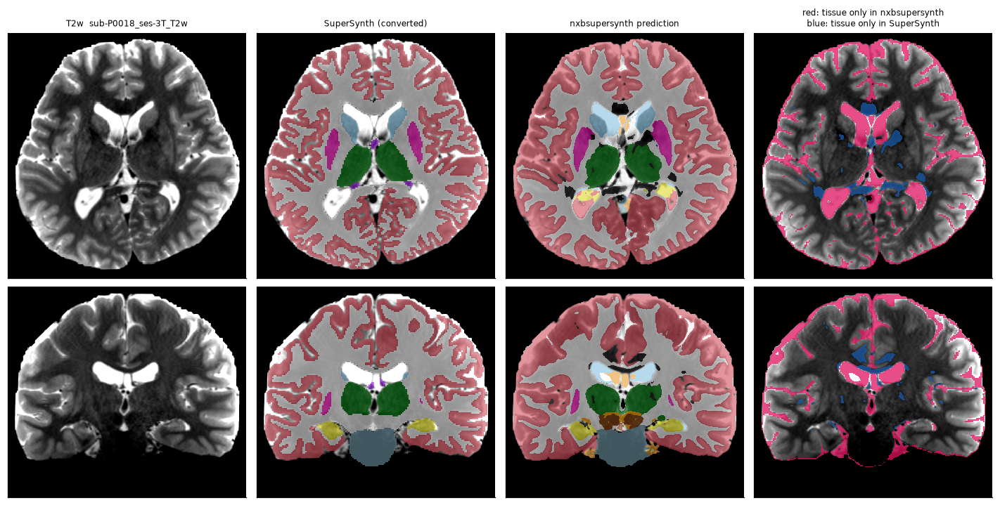

T2w: 300 mL tissue only in nxbsupersynth; original SuperSynth labels there:


,supersynth_label,name,mL,share_%
0,24,CSF,258.43,86.1
1,4,Left-Lateral-Ventricle,19.01,6.3
2,43,Right-Lateral-Ventricle,12.10,4.0
3,0,Unknown,5.49,1.8
4,15,4th-Ventricle,2.33,0.8
5,14,3rd-Ventricle,1.20,0.4


...and the nxbsupersynth labels it gets: {'WM': '11%', 'Cortex': '71%', 'Cb cortex': '8%', 'Caudate': '6%'}


In [8]:
rows = []
for fld in FIELDS:
    for c in CONTRASTS:
        t = per_case_all[(per_case_all.contrast == c) & (per_case_all.field == fld)].groupby("case")[["vol_gt_ml", "vol_pred_ml"]].sum()
        r = 100 * (t.vol_pred_ml - t.vol_gt_ml) / t.vol_gt_ml
        rows.append(dict(field=fld, contrast=c, supersynth_mL=t.vol_gt_ml.mean(), nxbsupersynth_mL=t.vol_pred_ml.mean(),
                         diff_pct_mean=r.mean(), diff_pct_std=r.std()))
print("Sum of the 18 structures (whole labeled brain), mean over cases:")
display(pd.DataFrame(rows).round(1))

for c in CONTRASTS:
    d = REP_CASES[c]; cen = centroid(d["gt"] > 0)
    fig, axs = plt.subplots(2, 4, figsize=(13, 6.8))
    for row, axis in enumerate((2, 1)):
        show_row(axs[row], d, axis, cen[axis], box=crop_box(d["gt"] > 0, axis, 5, d["zooms"]), err="tissue", title=(row == 0))
    plt.tight_layout(); plt.show()
    extra = (d["pred"] > 0) & (d["gt"] == 0)
    print(f"{c}: {extra.sum() * np.prod(d['zooms']) / 1000:.0f} mL tissue only in nxbsupersynth; original SuperSynth labels there:")
    display(raw_breakdown(d, extra, top=6))
    print("...and the nxbsupersynth labels it gets:",
          {SHORT[l]: f"{100 * n / extra.sum():.0f}%" for l, n in zip(*np.unique(d["pred"][extra], return_counts=True)) if n / extra.sum() > 0.02})

**What we see.** - The sum of the 18 structures is **+9 to +14 % on T1w/FLAIR and +24 % on T2w**, at 3T and 7T alike.
- **86–94 % of the extra tissue is SuperSynth CSF (24)**, and it is labeled cortex (71–84 %) or cerebellar cortex. SuperSynth
  labels the CSF in the sulci and around the brain; the network draws the cortex to the outer pial surface and fills the sulci.
  The training labels come from NextBrain, which has no CSF label inside the brain mask, so this is a definition
  difference: the cortical volume (+16 to +54 %) reflects it directly.
- On T2w, 5–10 % of the extra tissue is **lateral ventricle** (next section).

## 5. Finding: caudate over-segmented on T2w (ventricles)

Same subject, T1w vs T2w, crop around the caudate (label 7). The table lists the original SuperSynth
labels of the voxels that nxbsupersynth calls caudate but SuperSynth does not. Then a T2w case at the 90th
percentile of caudate over-segmentation.

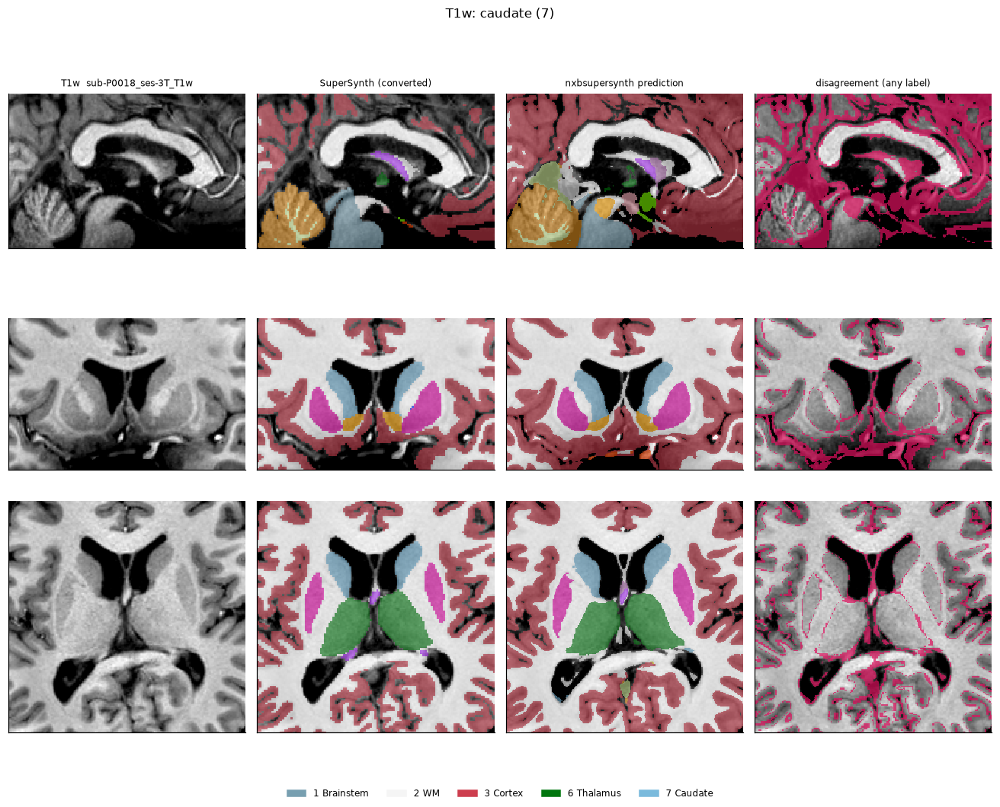

T1w: nxbsupersynth caudate outside SuperSynth caudate: 1.82 mL; SuperSynth labels:


,supersynth_label,name,mL,share_%
0,4,Left-Lateral-Ventricle,0.45,24.7
1,43,Right-Lateral-Ventricle,0.31,17.1
2,2,Left-Cerebral-White-Matter,0.28,15.6
3,41,Right-Cerebral-White-Matter,0.28,15.4
4,58,Right-Accumbens-area,0.16,8.7
5,26,Left-Accumbens-area,0.15,8.5


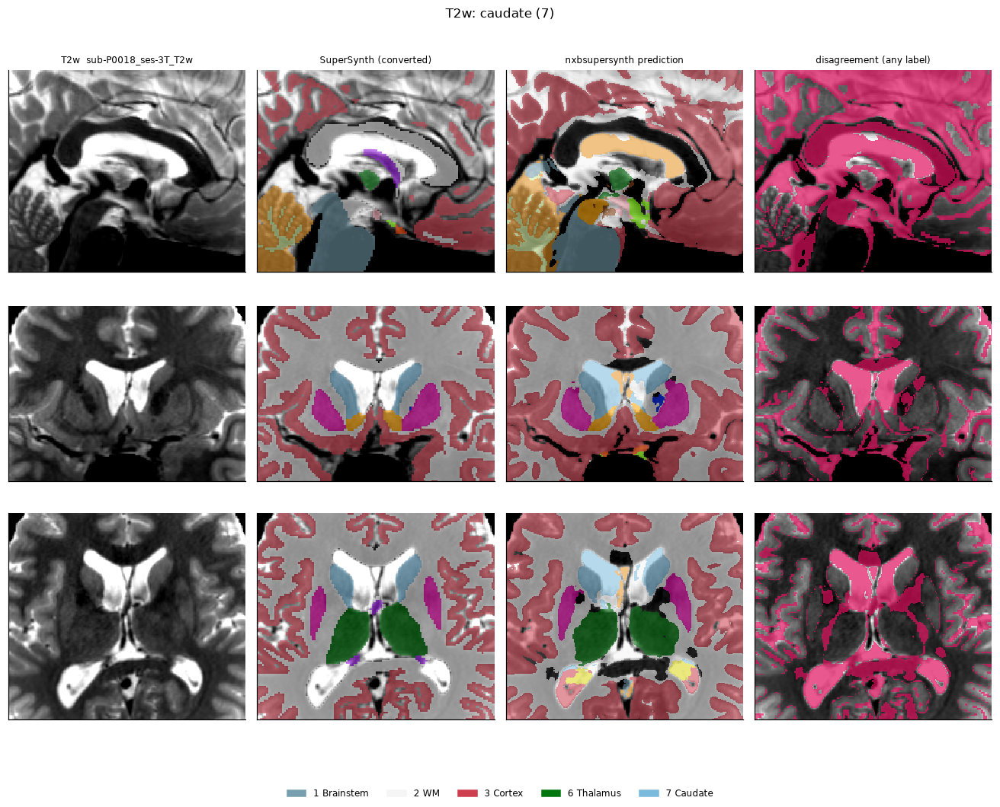

T2w: nxbsupersynth caudate outside SuperSynth caudate: 17.44 mL; SuperSynth labels:


,supersynth_label,name,mL,share_%
0,4,Left-Lateral-Ventricle,9.27,53.1
1,43,Right-Lateral-Ventricle,6.87,39.4
2,41,Right-Cerebral-White-Matter,0.24,1.4
3,44,Right-Inf-Lat-Vent,0.23,1.3
4,2,Left-Cerebral-White-Matter,0.22,1.3
5,5,Left-Inf-Lat-Vent,0.16,0.9


{'dice': 0.26, 'vol_gt_ml': 6.62, 'vol_pred_ml': 25.03, 'rel_vol_diff_pct': 278.21}


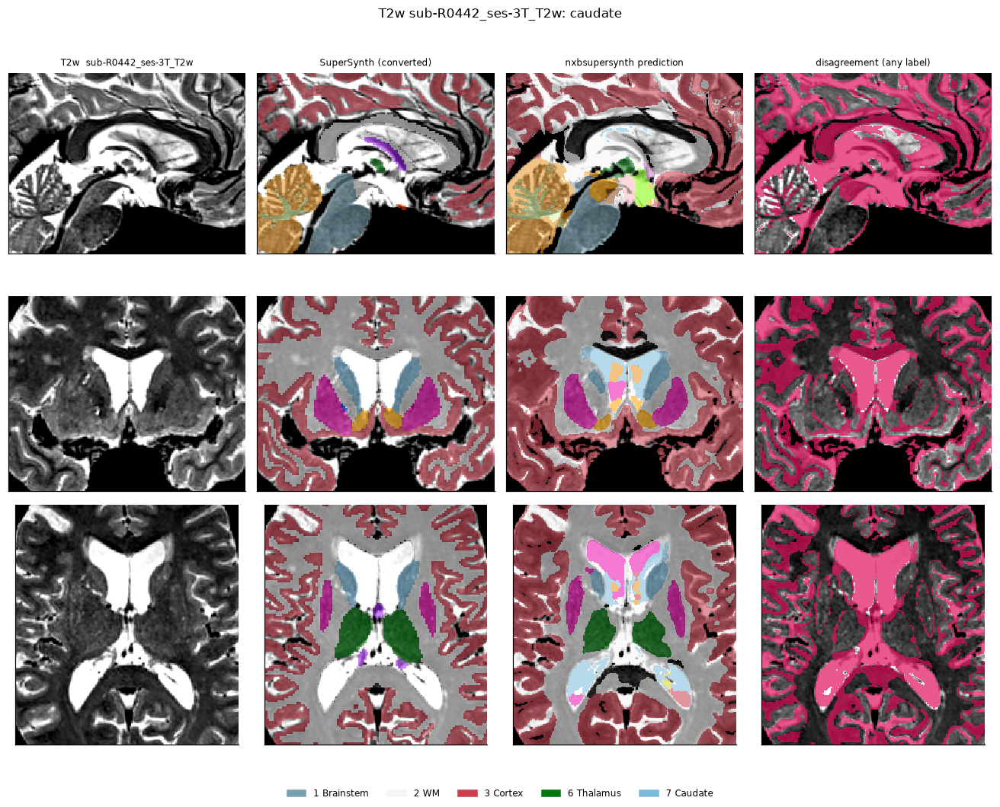

,supersynth_label,name,mL,share_%
0,4,Left-Lateral-Ventricle,9.26,44.4
1,43,Right-Lateral-Ventricle,9.04,43.4
2,77,WM-hypointensities,1.19,5.7
3,5,Left-Inf-Lat-Vent,0.54,2.6
4,41,Right-Cerebral-White-Matter,0.26,1.3
5,44,Right-Inf-Lat-Vent,0.18,0.8


In [9]:
for c in ["T1w", "T2w"]:
    d = REP_CASES[c]
    zoom_fig(d, [7], f"{c}: caudate (7)", margin=15)
    sel = (d["pred"] == 7) & (d["gt"] != 7)
    print(f"{c}: nxbsupersynth caudate outside SuperSynth caudate: {sel.sum() * np.prod(d['zooms']) / 1000:.2f} mL; SuperSynth labels:")
    display(raw_breakdown(d, sel, top=6))

cau = per_case[(per_case.contrast == "T2w") & (per_case.label == 7)].sort_values("rel_vol_diff_pct")
CAU_CASE = cau.iloc[int(0.9 * len(cau))].case
print(cau.set_index("case").loc[CAU_CASE, ["dice", "vol_gt_ml", "vol_pred_ml", "rel_vol_diff_pct"]].round(2).to_dict())
d = load_case("T2w", CAU_CASE)
zoom_fig(d, [7], f"T2w {CAU_CASE}: caudate", margin=15)
display(raw_breakdown(d, (d["pred"] == 7) & (d["gt"] != 7), top=6))

**What we see.** On T1w the predicted caudate overlaps SuperSynth's (1.8 mL extra, mostly its borders). On T2w there are 17 mL extra,
**92 % of it SuperSynth lateral ventricle**: the bright ventricle lumen is painted as caudate. At the 90th percentile the
caudate is ×3.8. Same failure as nxb16 on T2w.

## 6. Finding: accumbens, basal forebrain and mammillary bodies are *different structures* in the two label sets

The nxbsupersynth training labels come from NextBrain via `nextbrain_to_nxbsupersynth.yaml` (a copy of
`nextbrain-utils/.../NextBrainToSuperSynth.yaml`). Some SuperSynth class names there hold other anatomy:

| class (SuperSynth id) | NextBrain labels in the training mapping |
|---|---|
| Accumbens-area (58) | core of nucleus accumbens **+ diagonal band, optic tract, fasciculus retroflexus, ventral tegmental area, midbrain (384), peripeduncular nucleus, infundibular stalk** (the yaml comment: "looks more like ventral DC") |
| Basal-Forebrain (866) | **substantia nigra (reticular + compact), subthalamic nucleus (3 parts), red nucleus** |
| MammillaryBody (844) | mammillary nuclei **+ posterior hypothalamic nucleus, tuberomammillary nucleus, lateral hypothalamic area (posterior), supramammillary nucleus** |

SuperSynth's own accumbens / basal forebrain / mammillary body are the anatomical structures of those names.
The crops below show each label in both segmentations, and the tables list the original SuperSynth labels
under the predicted label.

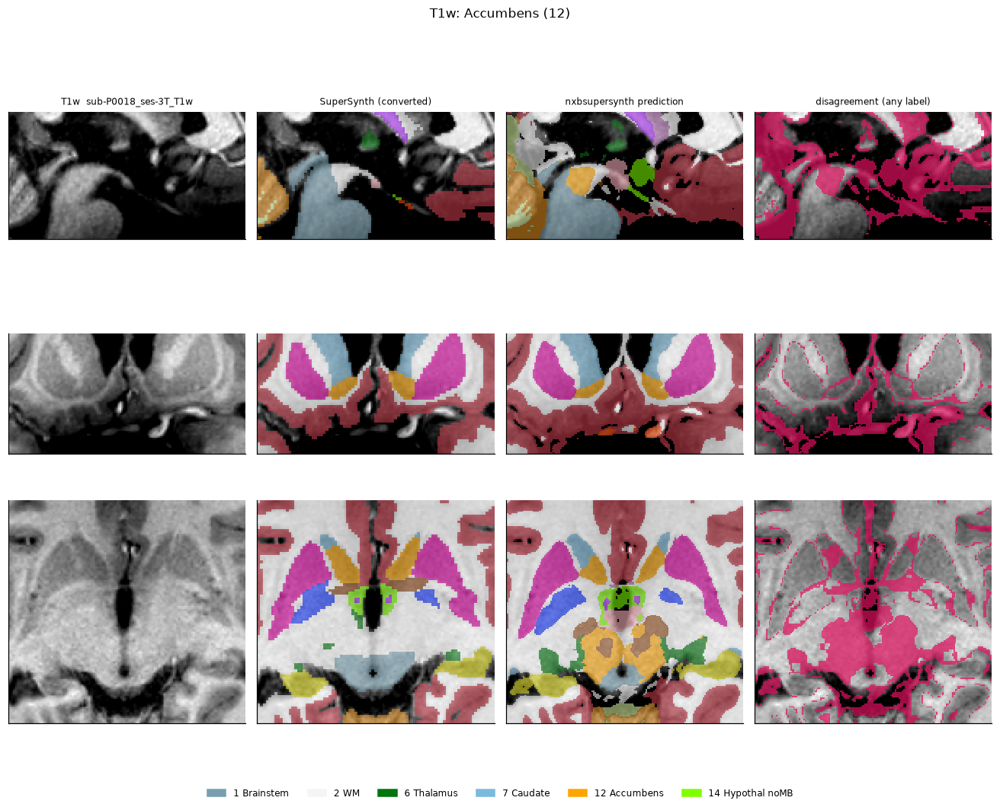

Accumbens: prediction 5.27 mL, SuperSynth 1.31 mL, overlap 0.77 mL; SuperSynth labels under the prediction:


,supersynth_label,name,mL,share_%
0,16,Brain-Stem,2.30,43.6
1,2,Left-Cerebral-White-Matter,0.65,12.4
2,41,Right-Cerebral-White-Matter,0.61,11.7
3,26,Left-Accumbens-area,0.39,7.4
4,58,Right-Accumbens-area,0.38,7.3
5,24,CSF,0.24,4.6


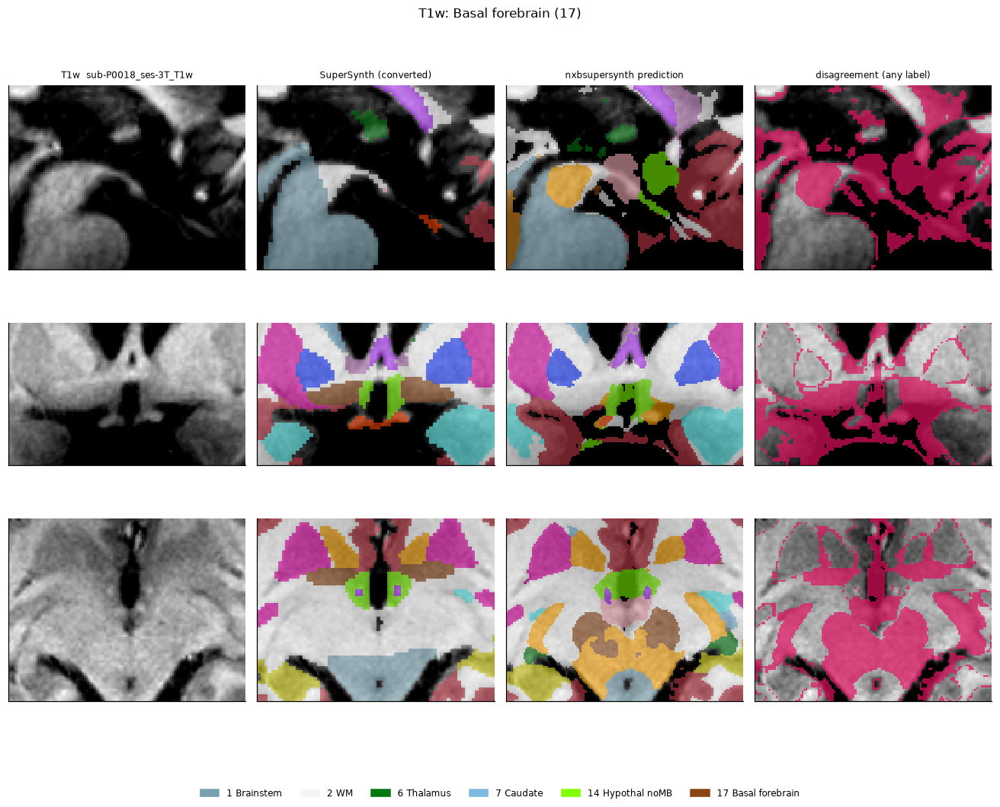

Basal forebrain: prediction 2.00 mL, SuperSynth 0.66 mL, overlap 0.00 mL; SuperSynth labels under the prediction:


,supersynth_label,name,mL,share_%
0,2,Left-Cerebral-White-Matter,0.91,45.5
1,41,Right-Cerebral-White-Matter,0.89,44.7
2,16,Brain-Stem,0.12,5.8
3,24,CSF,0.04,1.8
4,49,Right-Thalamus,0.03,1.5
5,10,Left-Thalamus,0.01,0.7


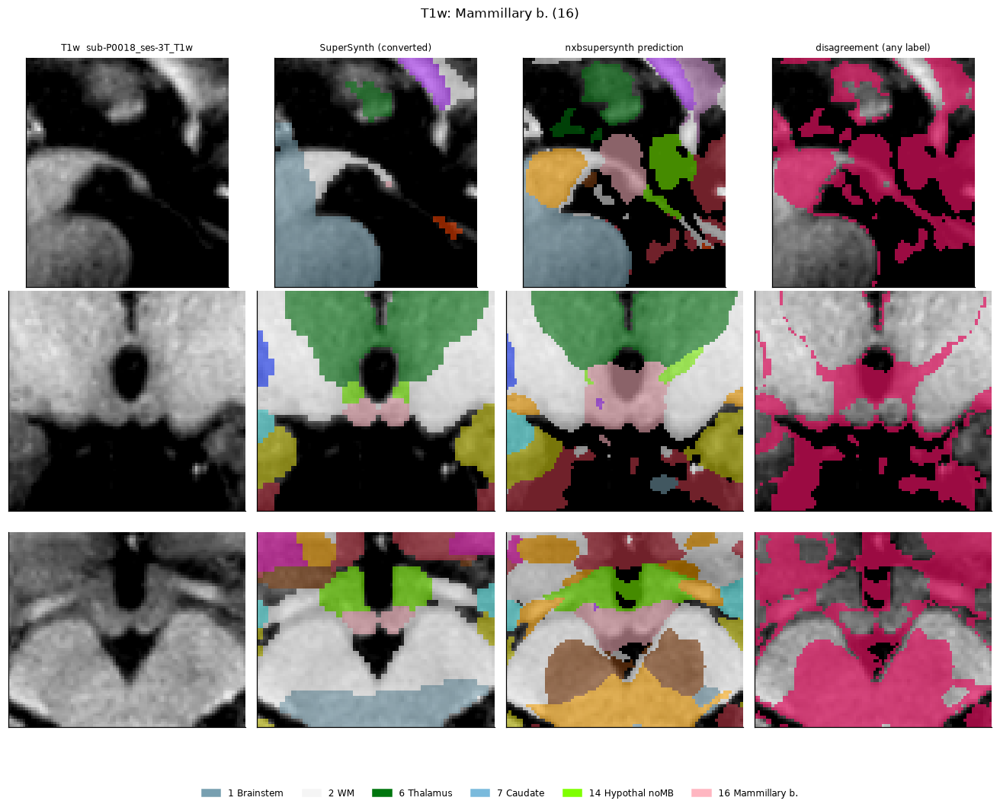

Mammillary b.: prediction 0.94 mL, SuperSynth 0.14 mL, overlap 0.14 mL; SuperSynth labels under the prediction:


,supersynth_label,name,mL,share_%
0,14,3rd-Ventricle,0.20,21.7
1,24,CSF,0.17,18.5
2,2,Left-Cerebral-White-Matter,0.13,13.7
3,41,Right-Cerebral-White-Matter,0.10,10.5
4,843,Left-MammillaryBody,0.07,7.3
5,844,Right-MammillaryBody,0.07,7.2


In [10]:
d = REP_CASES["T1w"]
for lab in (12, 17, 16):
    zoom_fig(d, [lab], f"T1w: {SHORT[lab]} ({lab})", margin=12, legend_extra=(1, 2, 6, 7, 14))
    pm, gm = d["pred"] == lab, d["gt"] == lab
    ml = np.prod(d["zooms"]) / 1000
    print(f"{SHORT[lab]}: prediction {pm.sum() * ml:.2f} mL, SuperSynth {gm.sum() * ml:.2f} mL, overlap {(pm & gm).sum() * ml:.2f} mL;"
          " SuperSynth labels under the prediction:")
    display(raw_breakdown(d, pm, top=6))

**What we see.** - **Accumbens (12):** the network draws a large region in the **upper midbrain / ventral diencephalon** (5.3 mL vs 1.3 mL in SuperSynth);
  44 % of it is SuperSynth brain stem and 24 % white matter. The real accumbens (below the caudate head) is also labeled, so Dice
  is 0.23–0.25 and the volume +280–315 %.
- **Basal forebrain (17):** the network's label sits on the **substantia nigra / subthalamic nucleus / red nucleus**, which SuperSynth labels as WM
  (SuperSynth has no ventral DC class here). SuperSynth's basal forebrain is the band below the striatum, which the network calls WM.
  **Zero overlap in every case** → Dice 0.000.
- **Mammillary body (16):** the network label includes the posterior hypothalamus, so it is 5–7× larger than SuperSynth's
  (it covers 90 % of SuperSynth's mammillary bodies, but Dice is 0.2–0.27).
- These three Dice values measure the mapping in `nextbrain_to_nxbsupersynth.yaml`, not the network. To compare with SuperSynth they
  should either be left out of the mean, or the training mapping should be changed to SuperSynth's definitions
  (e.g. a separate ventral-DC class for midbrain, SN, STN, RN, VTA; NextBrain's basal forebrain nuclei → Basal-Forebrain).

## 7. Finding: the worst T2w cases (`sub-R*`)

The three worst T2w 3T cases next to the same subject's T1w, mid-axial and mid-coronal.

,case,dice,abs_rel_vol_diff_pct
786,sub-R0411_ses-3T_T2w,0.212,73.979
746,sub-R0370_ses-3T_T2w,0.298,70.329
721,sub-R0345_ses-3T_T2w,0.320,60.096


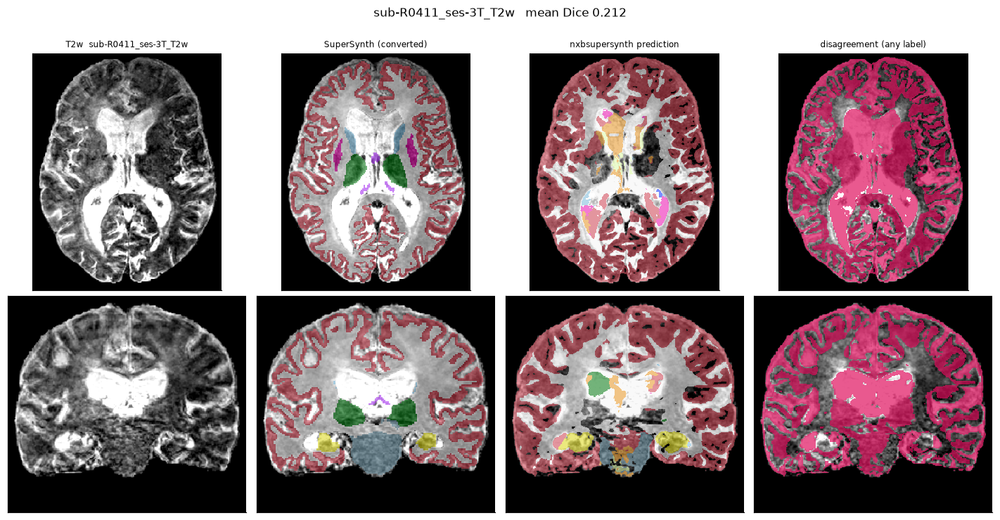

sub-R0411_ses-3T_T2w: SuperSynth ventricles 88 mL, of which labeled as tissue by nxbsupersynth: 83 mL


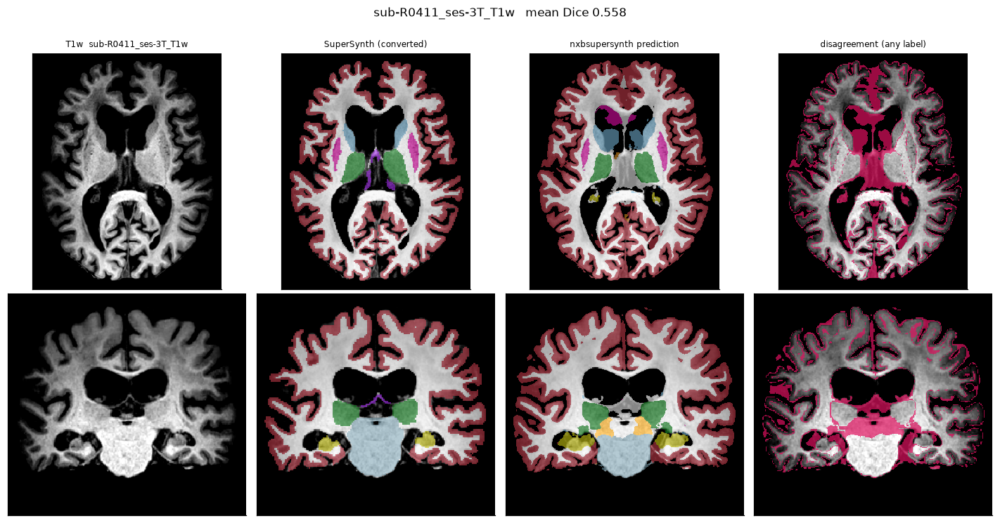

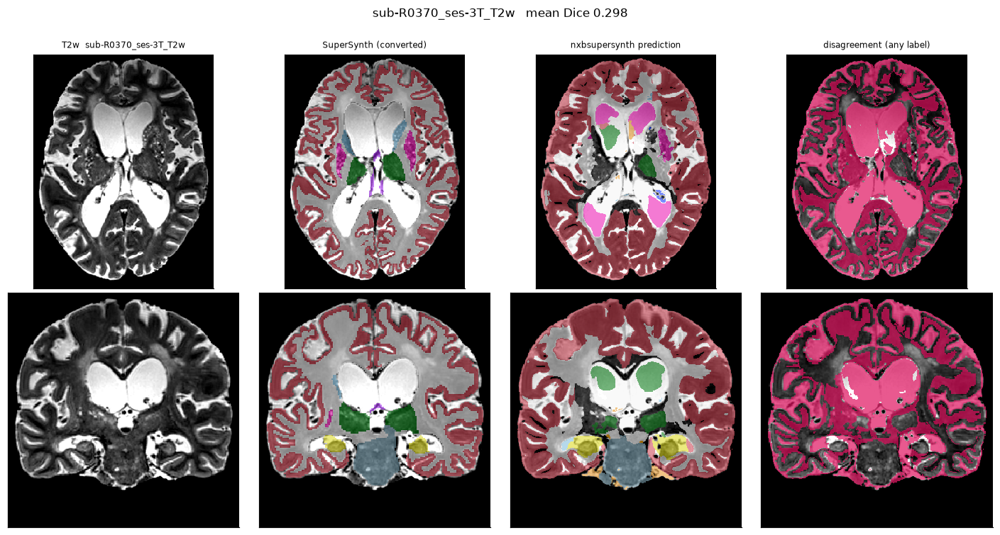

sub-R0370_ses-3T_T2w: SuperSynth ventricles 148 mL, of which labeled as tissue by nxbsupersynth: 137 mL


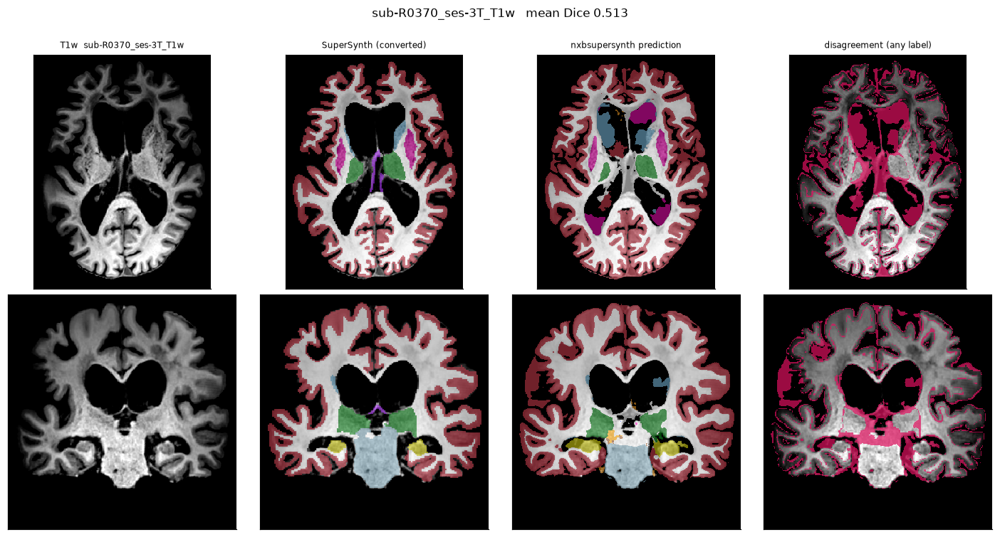

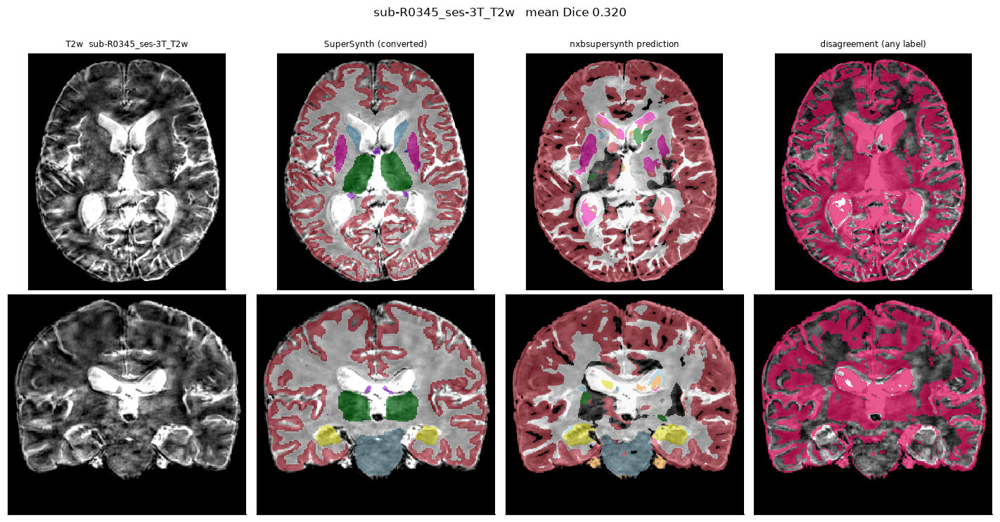

sub-R0345_ses-3T_T2w: SuperSynth ventricles 42 mL, of which labeled as tissue by nxbsupersynth: 39 mL


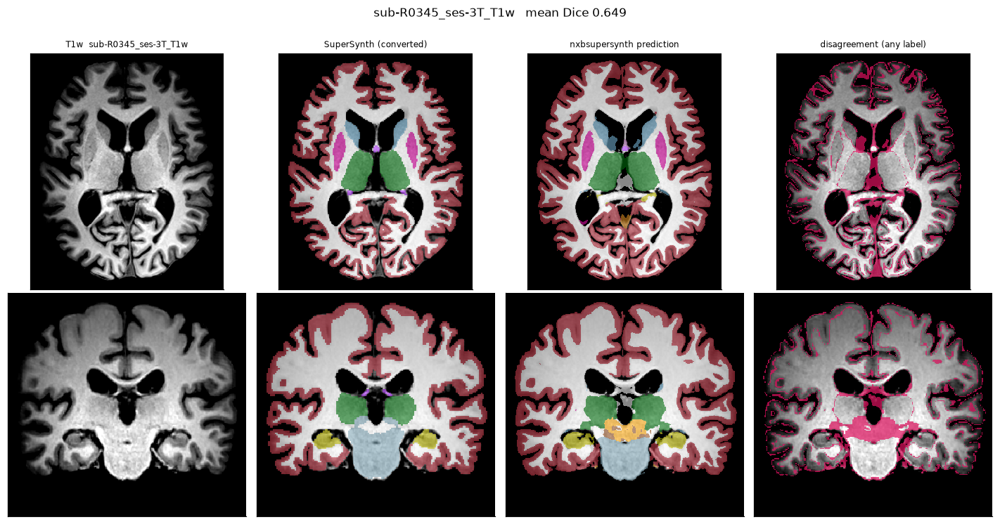

In [11]:
worst = per_case_mean[per_case_mean.contrast == "T2w"].nsmallest(3, "dice")
display(worst[["case", "dice", "abs_rel_vol_diff_pct"]].round(3))
for case in worst.case:
    sub = case.split("_")[0]
    for c in ["T2w", "T1w"]:
        cc = f"{sub}_ses-{FIELD}_{c}"
        if not (PRED / c / FIELD / f"{cc}.nii.gz").exists(): continue
        d = load_case(c, cc); cen = centroid(d["gt"] > 0)
        dc = per_case_mean[(per_case_mean.contrast == c) & (per_case_mean.case == cc)].dice.iloc[0]
        fig, axs = plt.subplots(2, 4, figsize=(13, 6.8))
        for row, axis in enumerate((2, 1)):
            show_row(axs[row], d, axis, cen[axis], box=crop_box(d["gt"] > 0, axis, 5, d["zooms"]), title=(row == 0))
        fig.suptitle(f"{cc}   mean Dice {dc:.3f}", y=1.0); plt.tight_layout(); plt.show()
        if c == "T2w":
            m = (d["pred"] > 0) & np.isin(d["raw"], [4, 5, 43, 44, 14, 15])
            print(f"{cc}: SuperSynth ventricles {np.isin(d['raw'], [4, 5, 43, 44, 14, 15]).sum() * np.prod(d['zooms']) / 1000:.0f} mL,"
                  f" of which labeled as tissue by nxbsupersynth: {m.sum() * np.prod(d['zooms']) / 1000:.0f} mL")

**What we see.** The worst T2w cases (`sub-R0411`, `sub-R0370`, `sub-R0345`) have **large ventricles** (42–148 mL in SuperSynth) and
bright white-matter lesions on T2w. **93–94 % of their ventricle volume is labeled as tissue** by the network (caudate, putamen,
thalamus, accumbens colors), and the deep gray structures around them break down. The same subjects are segmented normally
on T1w. Same cases and same failure as nxb16.

## 8. Finding: small structures

Dice vs SuperSynth volume per case and structure, and whether per-subject volumes track SuperSynth (Pearson r).

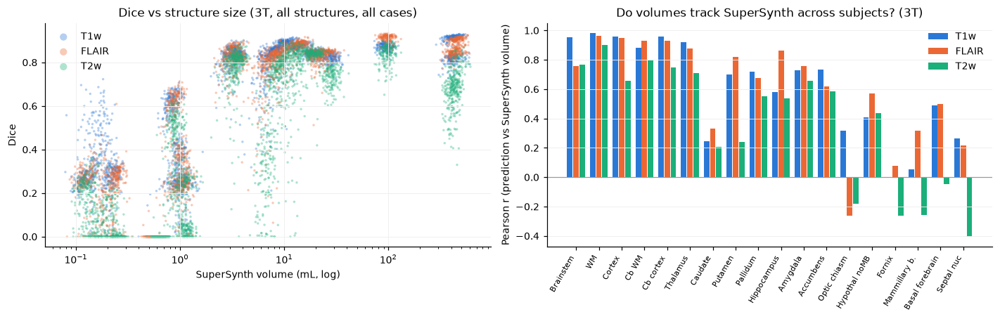

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
for c in CONTRASTS:
    t = per_case[per_case.contrast == c]
    axs[0].scatter(t.vol_gt_ml, t.dice, s=5, alpha=0.35, color=CCOL[c], label=c, edgecolor="none")
axs[0].set_xscale("log"); axs[0].set_xlabel("SuperSynth volume (mL, log)"); axs[0].set_ylabel("Dice")
axs[0].legend(frameon=False, markerscale=3); axs[0].set_title("Dice vs structure size (3T, all structures, all cases)")
axs[0].grid(color="#eee", lw=0.6)
r = summ[summ.label > 0].pivot(index="label", columns="contrast", values="vol_pearson_r")[CONTRASTS]
x = np.arange(NS); w = 0.27
for i, c in enumerate(CONTRASTS):
    axs[1].bar(x + (i - 1) * w, r[c].values, w * 0.9, color=CCOL[c], label=c)
axs[1].set_xticks(x); axs[1].set_xticklabels([SHORT[l] for l in r.index], rotation=60, ha="right", fontsize=7.5)
axs[1].axhline(0, color="#999", lw=0.8); axs[1].set_ylabel("Pearson r (prediction vs SuperSynth volume)")
axs[1].set_title("Do volumes track SuperSynth across subjects? (3T)"); axs[1].legend(frameon=False)
axs[1].grid(axis="y", color="#eee", lw=0.6)
plt.tight_layout(); plt.show()

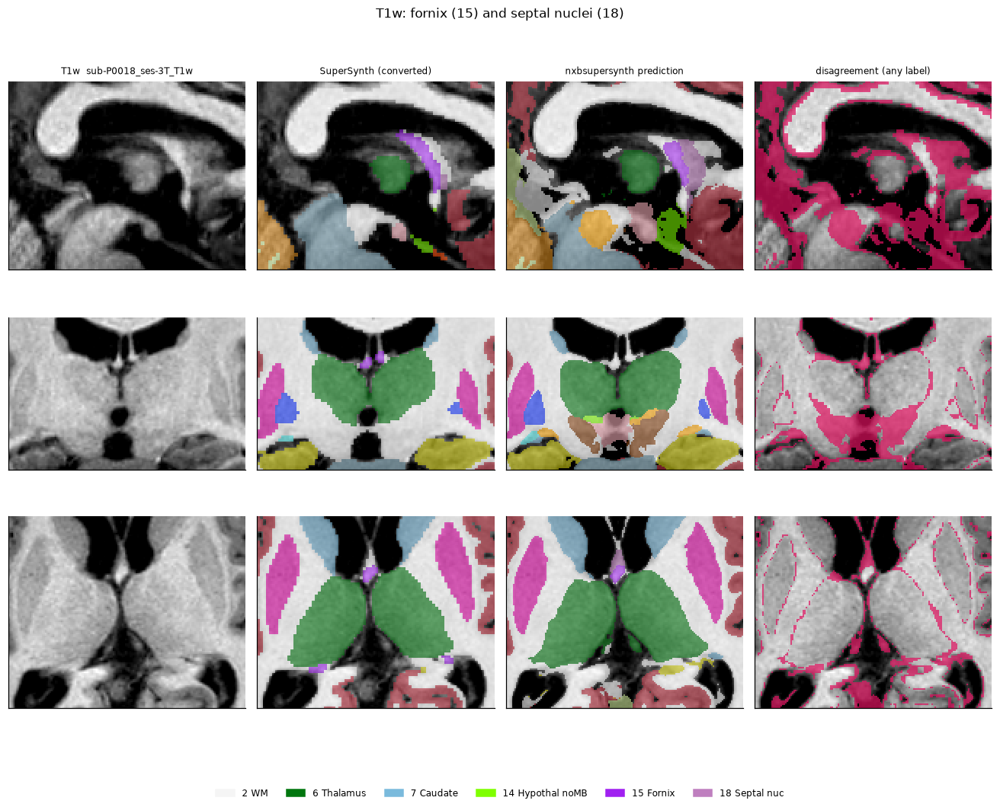

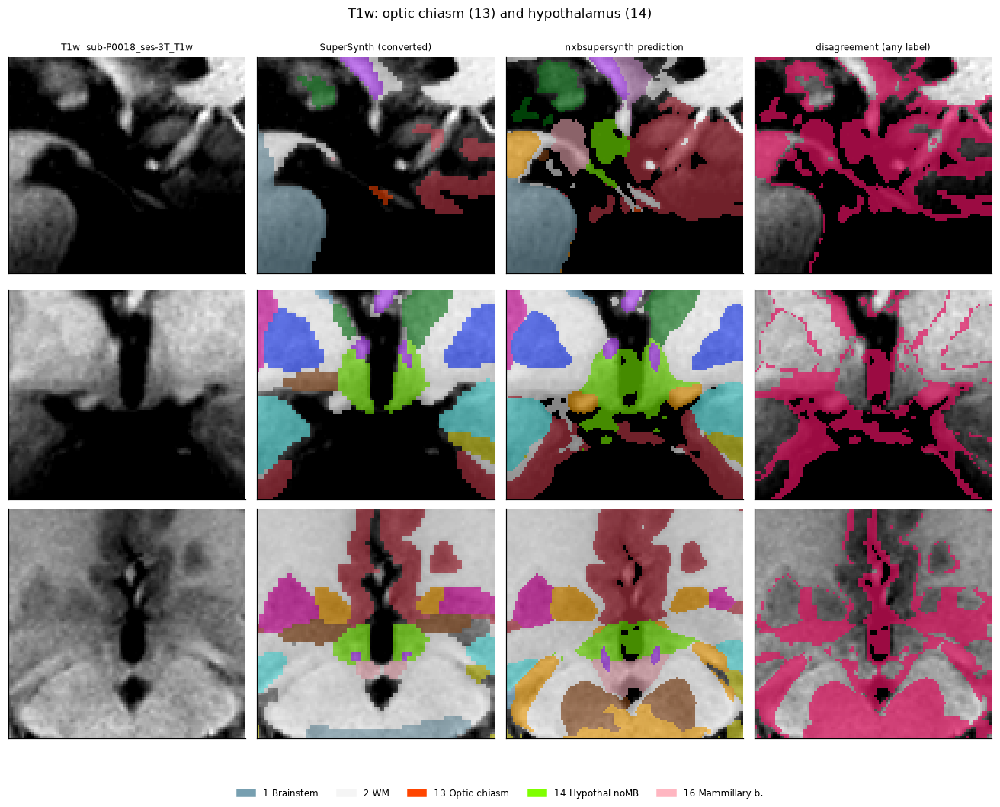

In [13]:
d = REP_CASES["T1w"]
zoom_fig(d, [15, 18], "T1w: fornix (15) and septal nuclei (18)", margin=10, legend_extra=(2, 6, 7, 14))
zoom_fig(d, [13, 14], "T1w: optic chiasm (13) and hypothalamus (14)", margin=10, legend_extra=(1, 2, 16))

**What we see.** Below ~2 mL Dice spreads between 0 and 0.7 and the per-subject volumes barely track SuperSynth (|r| < 0.5).
Fornix and septal nuclei are thin structures that the network labels mostly as WM (−66 to −96 % fornix volume); on T2w the
fornix (0.03–0.04 Dice) and septal nuclei (0.06–0.07) almost disappear. The optic chiasm matches on T1w (0.42 at 3T) but not on
FLAIR/T2w (< 0.15). Hypothalamus (0.41–0.62) is the best of the small structures.

## 9. 7T: are the same patterns there?

A `sub-P*` subject at 7T (closest to the 7T medians in the three contrasts) with the extra/missing tissue
map and the T2w caudate, then the worst 7T T2w cases.

7T representative subject: sub-P0007 {'FLAIR': 0.593, 'T1w': 0.635, 'T2w': 0.531}  medians: {'FLAIR': 0.593, 'T1w': 0.633, 'T2w': 0.521}


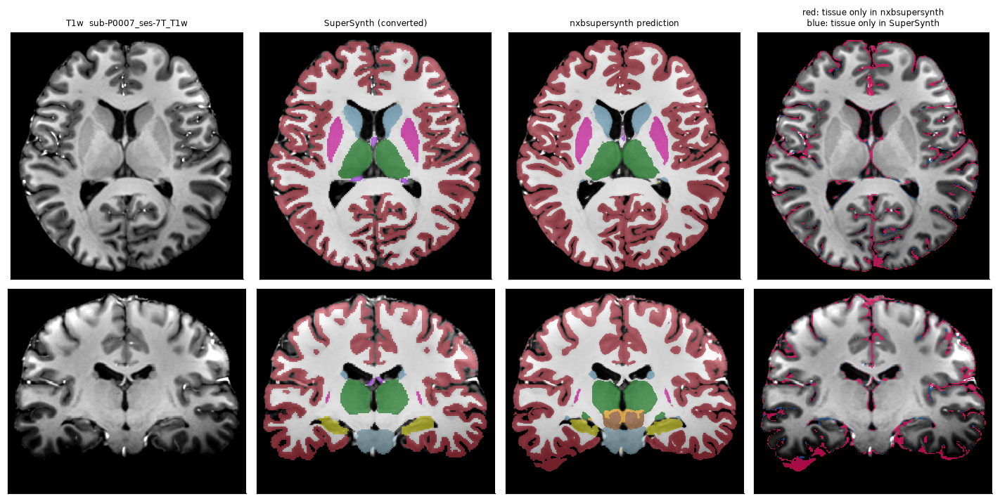

T1w 7T: 145 mL tissue only in nxbsupersynth; SuperSynth labels there:


,supersynth_label,name,mL,share_%
0,24,CSF,123.39,84.9
1,0,Unknown,12.70,8.7
2,915,Bone-Cortical,3.55,2.4
3,4,Left-Lateral-Ventricle,1.54,1.1


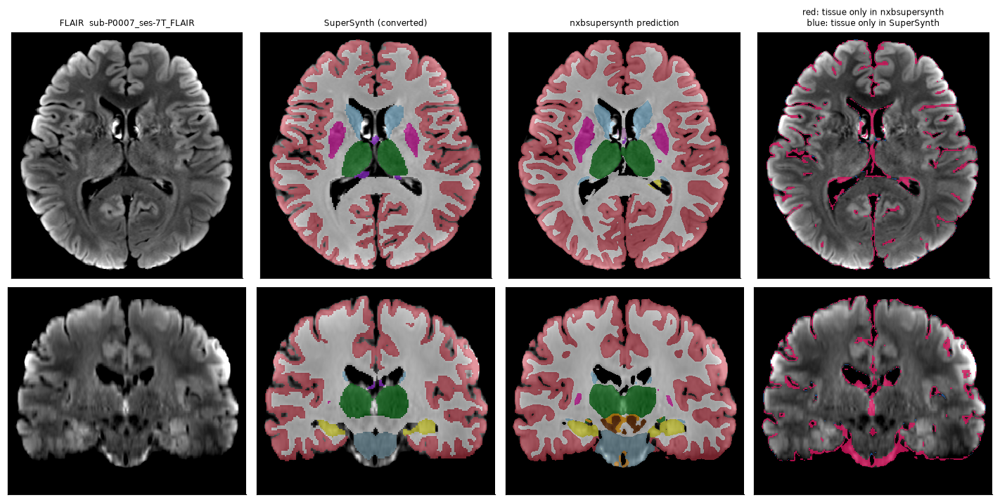

FLAIR 7T: 125 mL tissue only in nxbsupersynth; SuperSynth labels there:


,supersynth_label,name,mL,share_%
0,24,CSF,111.13,89.0
1,0,Unknown,4.32,3.5
2,4,Left-Lateral-Ventricle,3.65,2.9
3,43,Right-Lateral-Ventricle,2.63,2.1


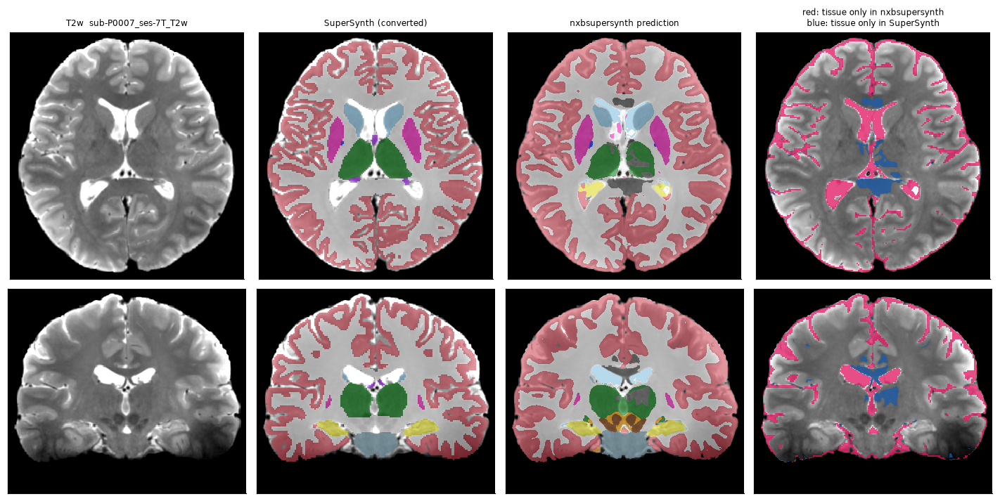

T2w 7T: 234 mL tissue only in nxbsupersynth; SuperSynth labels there:


,supersynth_label,name,mL,share_%
0,24,CSF,201.81,86.4
1,4,Left-Lateral-Ventricle,12.63,5.4
2,0,Unknown,8.36,3.6
3,43,Right-Lateral-Ventricle,7.40,3.2


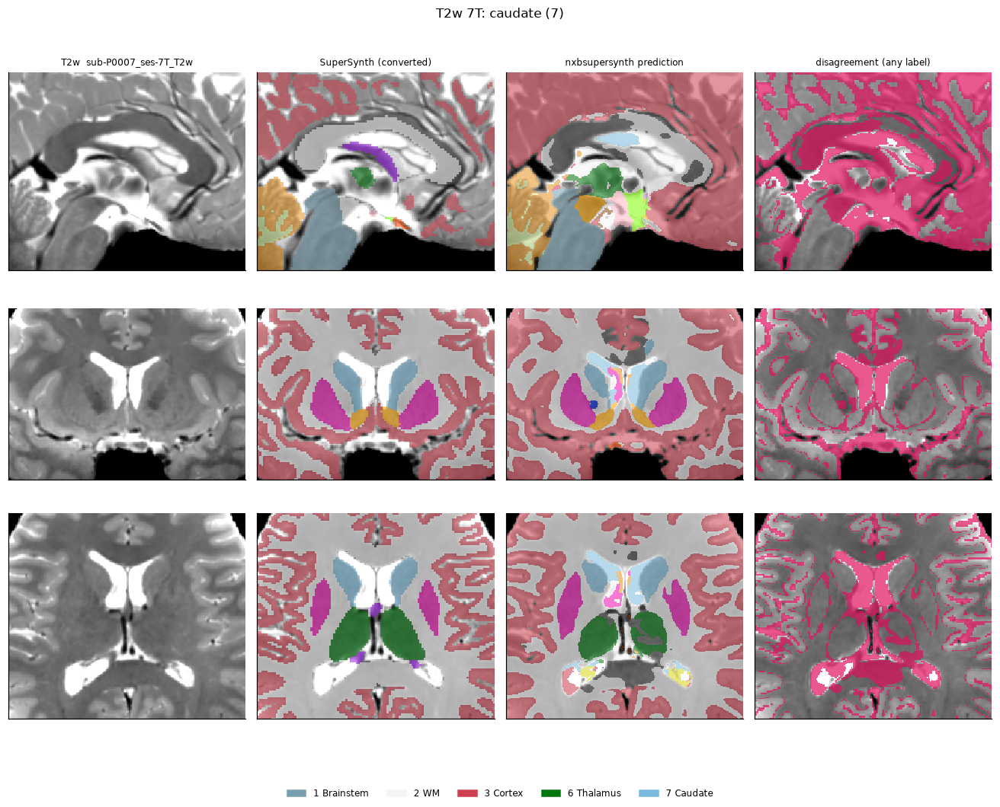

,supersynth_label,name,mL,share_%
0,4,Left-Lateral-Ventricle,6.79,51.2
1,43,Right-Lateral-Ventricle,4.96,37.3
2,41,Right-Cerebral-White-Matter,0.55,4.1
3,2,Left-Cerebral-White-Matter,0.19,1.5


In [14]:
q7 = per_case_mean_all[per_case_mean_all.field == "7T"]
wide7 = q7.pivot_table(index="subject", columns="contrast", values="dice").dropna()
med7 = q7.groupby("contrast").dice.median()
score7 = (wide7[CONTRASTS] - med7[CONTRASTS]).abs().sum(axis=1)
REP7 = score7[score7.index.str.startswith("sub-P")].idxmin()
print("7T representative subject:", REP7, wide7.loc[REP7].round(3).to_dict(), " medians:", med7.round(3).to_dict())
REP7_CASES = {c: load_case(c, f"{REP7}_ses-7T_{c}") for c in CONTRASTS}
for c in CONTRASTS:
    d = REP7_CASES[c]; cen = centroid(d["gt"] > 0)
    fig, axs = plt.subplots(2, 4, figsize=(13, 6.8))
    for row, axis in enumerate((2, 1)):
        show_row(axs[row], d, axis, cen[axis], box=crop_box(d["gt"] > 0, axis, 5, d["zooms"]), err="tissue", title=(row == 0))
    plt.tight_layout(); plt.show()
    extra = (d["pred"] > 0) & (d["gt"] == 0)
    print(f"{c} 7T: {extra.sum() * np.prod(d['zooms']) / 1000:.0f} mL tissue only in nxbsupersynth; SuperSynth labels there:")
    display(raw_breakdown(d, extra, top=4))
d = REP7_CASES["T2w"]
zoom_fig(d, [7], "T2w 7T: caudate (7)", margin=15)
display(raw_breakdown(d, (d["pred"] == 7) & (d["gt"] != 7), top=4))

,case,dice,abs_rel_vol_diff_pct
947,sub-R0821_ses-7T_T2w,0.372,43.351
886,sub-R0757_ses-7T_T2w,0.385,57.747
916,sub-R0789_ses-7T_T2w,0.426,64.865


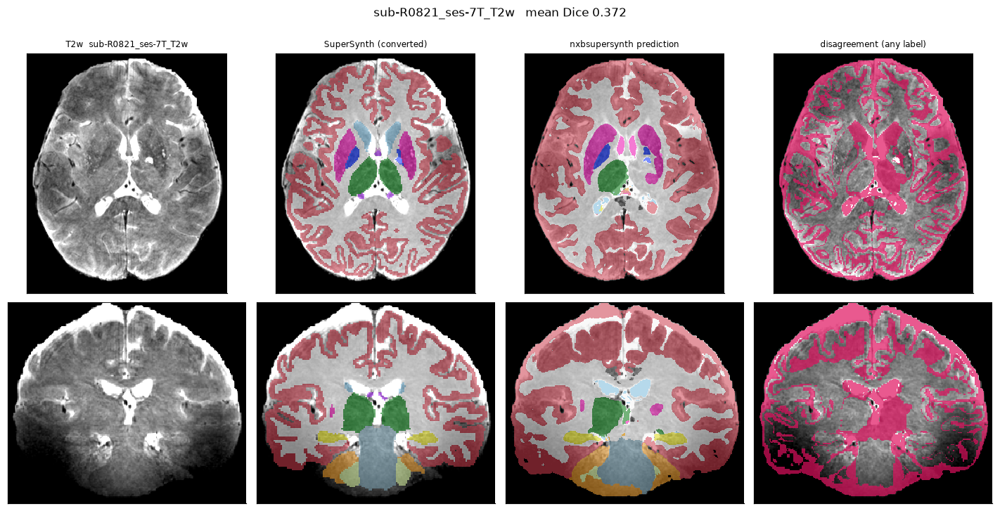

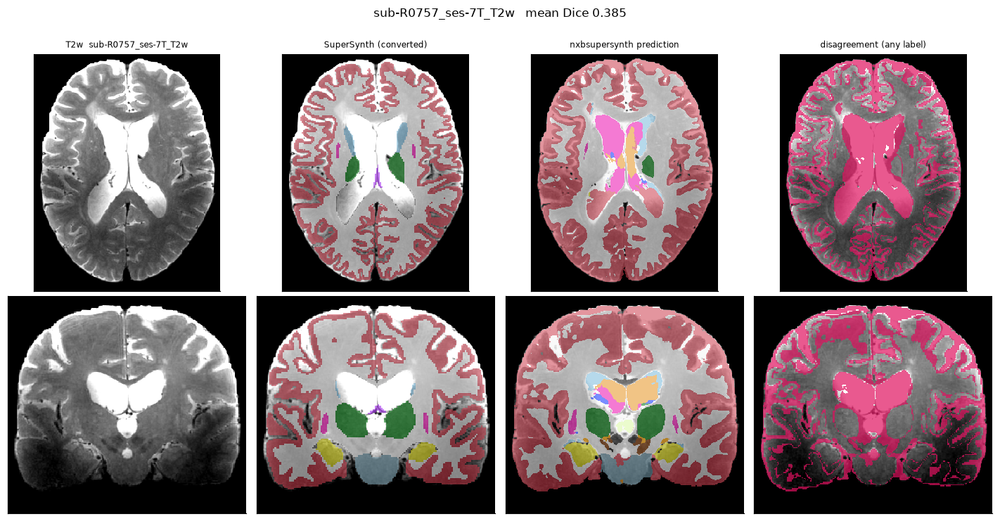

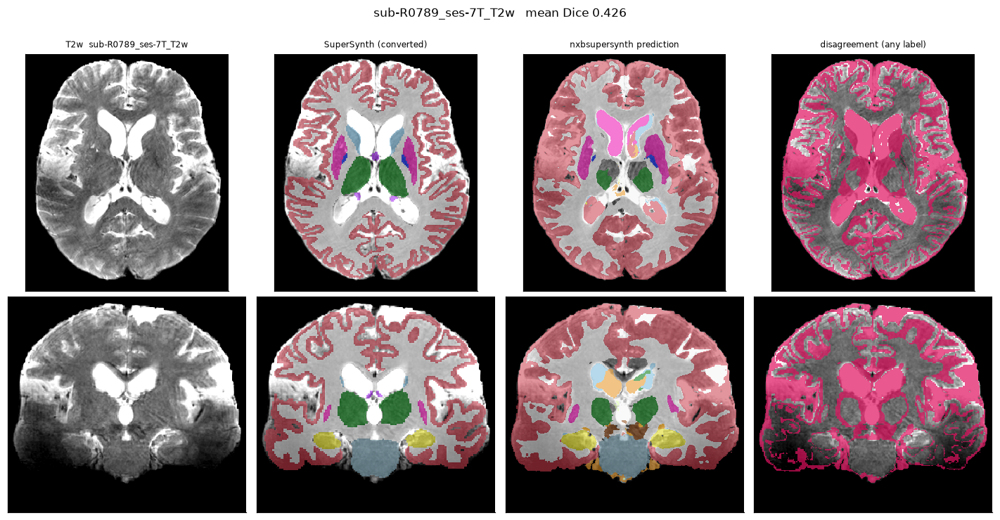

In [15]:
worst7 = q7[q7.contrast == "T2w"].nsmallest(3, "dice")
display(worst7[["case", "dice", "abs_rel_vol_diff_pct"]].round(3))
for case in worst7.case:
    sub = case.split("_")[0]
    for c in ["T2w", "T1w"]:
        cc = f"{sub}_ses-7T_{c}"
        if not (PRED / c / "7T" / f"{cc}.nii.gz").exists(): continue
        d = load_case(c, cc); cen = centroid(d["gt"] > 0)
        dc = q7[(q7.contrast == c) & (q7.case == cc)].dice.iloc[0]
        fig, axs = plt.subplots(2, 4, figsize=(13, 6.8))
        for row, axis in enumerate((2, 1)):
            show_row(axs[row], d, axis, cen[axis], box=crop_box(d["gt"] > 0, axis, 5, d["zooms"]), title=(row == 0))
        fig.suptitle(f"{cc}   mean Dice {dc:.3f}", y=1.0); plt.tight_layout(); plt.show()

**What we see (7T).** The same patterns as at 3T (`sub-P0007`):
- Extra tissue is again 85–89 % SuperSynth CSF labeled as cortex; on T2w the lateral ventricles are again labeled caudate
  (12 mL of SuperSynth ventricle under the extra caudate).
- Worst 7T T2w cases: `sub-R0757` and `sub-R0789` have enlarged ventricles filled with tissue labels. `sub-R0821` is the
  **image-quality failure** already seen with nxb16: the lower half of the image is dark (B1 inhomogeneity), the cortex rim is
  oversegmented at the top and the brainstem/cerebellum labels are lost; its T1w is normal.